A primeira célula será usada para importar todas as bibliotecas necessárias para o projeto.
Será atualizada conforme necessidade.

In [172]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [173]:
df = pd.read_csv('data/manutencao_preditiva.csv')

### Fase 1
As células abaixo serão de verificação de formato e informações do data frame.

In [174]:
# O método info mostra o formato do dataframe (linhas e colunas)
# bem como linhas não nulas e dtypes
# Não usei .shape por ser redundante nesse caso na minha visão
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   udi                      10000 non-null  int64  
 1   id_produto               10000 non-null  object 
 2   tipo                     10000 non-null  object 
 3   temperatura_ar_k         9500 non-null   float64
 4   temperatura_processo_k   9500 non-null   float64
 5   velocidade_rotacao_rpm   9500 non-null   float64
 6   torque_nm                9500 non-null   float64
 7   desgaste_ferramenta_min  10000 non-null  int64  
 8   falha_maquina            10000 non-null  int64  
 9   falha_twf                10000 non-null  int64  
 10  falha_hdf                10000 non-null  int64  
 11  falha_pwf                10000 non-null  int64  
 12  falha_osf                10000 non-null  int64  
 13  falha_rnf                10000 non-null  int64  
dtypes: float64(4), int64(8)

14 colunas e 10000 linhas

In [175]:
df.head()

,udi,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
0,1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
3,4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


In [176]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
udi,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
temperatura_ar_k,9500.0,300.002158,2.001689,295.3,298.30,300.1,301.50,304.5
temperatura_processo_k,9500.0,310.000895,1.486432,305.7,308.80,310.1,311.10,313.8
velocidade_rotacao_rpm,9500.0,1539.245263,180.273589,1168.0,1423.00,1504.0,1613.00,2886.0
torque_nm,9500.0,39.974168,9.995453,3.8,33.10,40.1,46.70,76.6
desgaste_ferramenta_min,10000.0,107.951000,63.654147,0.0,53.00,108.0,162.00,253.0
falha_maquina,10000.0,0.033900,0.180981,0.0,0.00,0.0,0.00,1.0
falha_twf,10000.0,0.004600,0.067671,0.0,0.00,0.0,0.00,1.0
falha_hdf,10000.0,0.011500,0.106625,0.0,0.00,0.0,0.00,1.0
falha_pwf,10000.0,0.009500,0.097009,0.0,0.00,0.0,0.00,1.0


As colunas udi e todas as colunas "falha", apesar de conterem números, são, no caso de udi, um identificador numérico e, no caso das "falhas", identificadores de estado true/false. Os resultados dessas colunas no describe não têm sentido prático, mas foram mantidos por ter sido um primeiro olhar para o df.

In [177]:
variaveis_preditivas = df.drop(columns=['udi','id_produto','falha_twf','falha_hdf','falha_pwf','falha_osf','falha_rnf'])


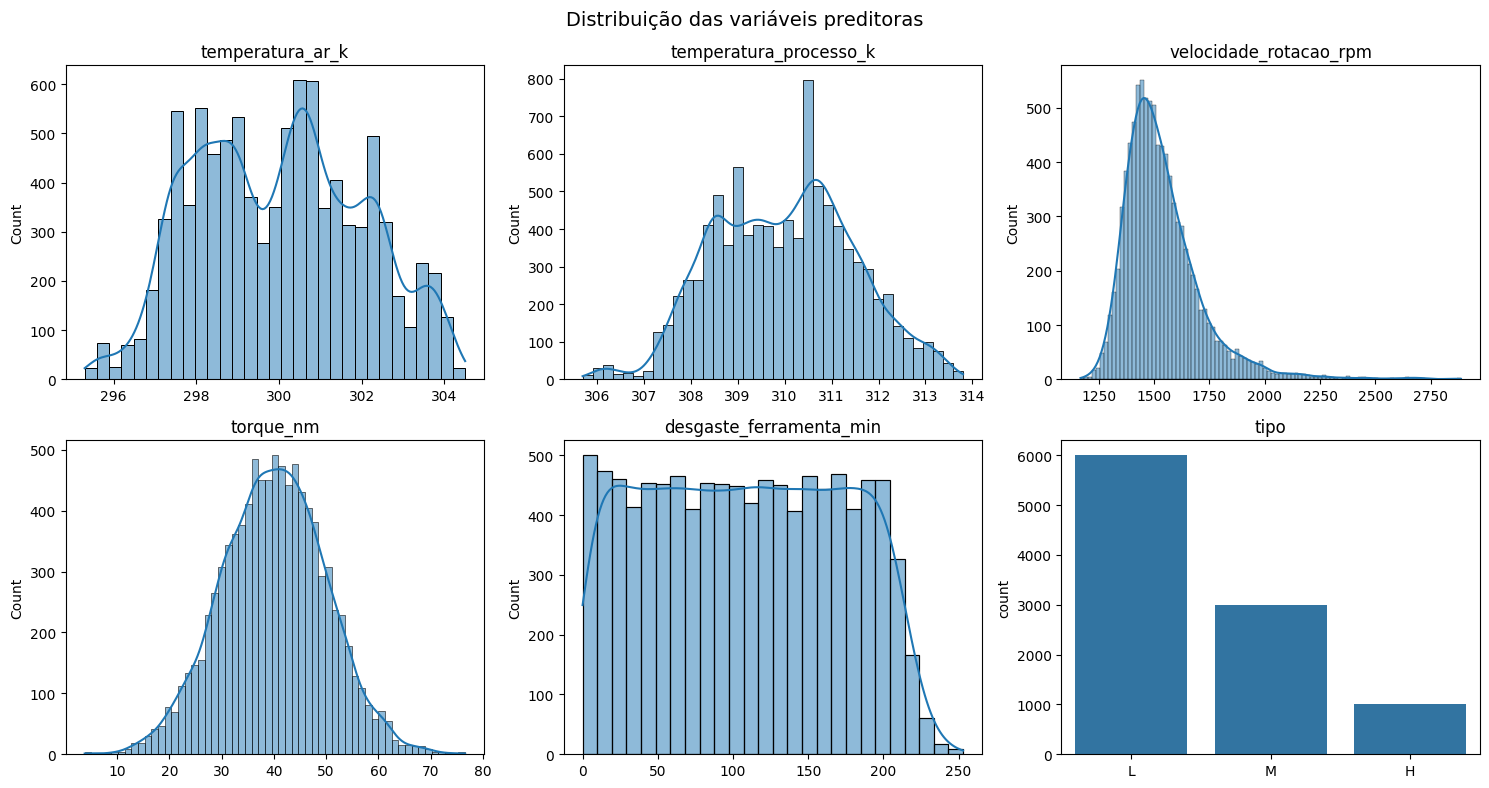

In [178]:
# separa as variáveis preditoras por tipo de variável
continuas = ['temperatura_ar_k', 'temperatura_processo_k',
             'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']
categoricas = ['tipo']

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()

# o loop percorre as contínuas (histograma + KDE)
for i, col in enumerate(continuas):
    sns.histplot(data=df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel('')

# exibe uma variável de tipo de maneira organizada
sns.countplot(data=df, x='tipo', order=['L', 'M', 'H'], ax=axes[5])
axes[5].set_title('tipo')
axes[5].set_xlabel('')

fig.suptitle('Distribuição das variáveis preditoras', fontsize=14)
plt.tight_layout()
plt.show()


In [179]:
print(f'Temperatura ar média: {df['temperatura_ar_k'].mean():.2f}, mediana: {df['temperatura_ar_k'].median():.2f}')
print(f'Temperatura processo média: {df['temperatura_processo_k'].mean():.2f}, mediana: {df['temperatura_processo_k'].median():.2f}')
print(f'Rotação média: {df['velocidade_rotacao_rpm'].mean():.2f}, mediana: {df['velocidade_rotacao_rpm'].median():.2f}')
print(f'Torque média: {df['torque_nm'].mean():.2f}, mediana: {df['torque_nm'].median():.2f}')

Temperatura ar média: 300.00, mediana: 300.10
Temperatura processo média: 310.00, mediana: 310.10
Rotação média: 1539.25, mediana: 1504.00
Torque média: 39.97, mediana: 40.10


Os valores de média e mediana acima foram calculados para entender que tipo de valor utilizar em caso de imputação nos valores NaN, só foi calculado para colunas com valores NaN.

Nos histogramas, a velocidade de rotação é a única variável com distribuição claramente assimétrica, com cauda à direita. Nesses casos, a mediana pode ser a melhor escolha para completar dados faltantes. As temperaturas do ar e do processo e o torque têm formato de sino, praticamente simétricos, com média e mediana quase iguais, então aqui é seguro usar a média. O desgaste da ferramenta é mais plano, distribuído de forma parecida entre 0 e 200 minutos, com uma queda a partir disso.

O tipo de equipamento é uma variável categórica, e aqui só a usamos para ver a distribuição entre os diferentes tipos. Ela deve ser levada em conta na hora de construir o modelo.

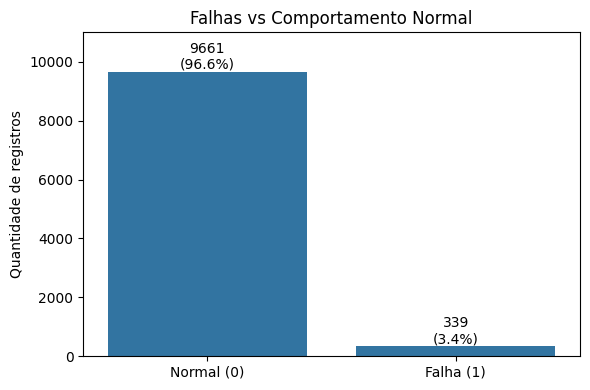

In [180]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='falha_maquina', ax=ax)

# mostra contagem e percentual em cima de cada barra
total = len(df)
for barra in ax.patches:
    altura = barra.get_height() # type: ignore
    ax.annotate(f'{altura:.0f}\n({altura / total:.1%})',
                (barra.get_x() + barra.get_width() / 2, altura), # type: ignore
                ha='center', va='bottom')

ax.set_xticks([0, 1], ['Normal (0)', 'Falha (1)'])
ax.set_title('Falhas vs Comportamento Normal')
ax.set_ylim(0, total * 1.1)   # o eixo vai até 10% acima do total de registros
ax.set_xlabel('')
ax.set_ylabel('Quantidade de registros')
plt.tight_layout()
plt.show()


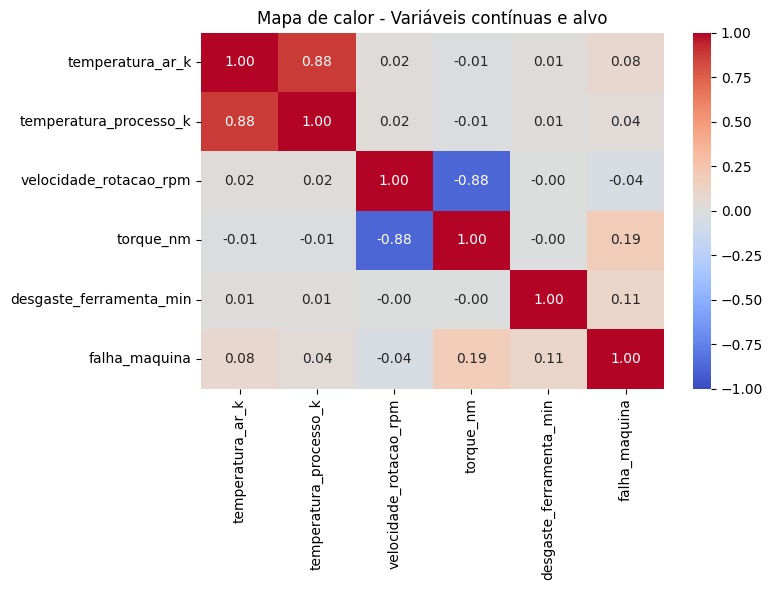

In [181]:
colunas_corr = continuas + ['falha_maquina']
correlacao = df[colunas_corr].corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlacao, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title('Mapa de calor - Variáveis contínuas e alvo')
plt.tight_layout()
plt.show()


O gráfico de barras mostra que a base é bastante desbalanceada: só 3,39% dos registros são falha (339 de 10000), contra 96,61% de funcionamento normal. Isso caracteriza um desbalanceamento severo (acima de 20:1), que requer um tratamento diferenciado, descrito na seção apropriada.

No mapa de calor, nenhuma variável tem correlação forte com a falha. A maior é a do torque (0,19), seguida pela do desgaste da ferramenta (0,11), o que faz sentido: máquina fazendo mais força e ferramenta mais gasta tendem a quebrar mais.

Aparece uma correlação forte e negativa entre torque e rotação (-0,88), que é uma característica da física dessas grandezas. Podemos usá-las para obter um indicador único de potência = torque x rotação, que pode ser mais útil para o modelo.

### Fase 2

Nesta fase serão feitos a análise de duplicados e o tratamento dos dados faltantes.

In [182]:
df.duplicated().sum()

np.int64(0)

In [183]:
print("Valores repetidos em udi:", df["udi"].duplicated().sum())
print("Valores repetidos em id_produto:", df["id_produto"].duplicated().sum())

Valores repetidos em udi: 0
Valores repetidos em id_produto: 0


Como os identificadores (udi e id_produto) são únicos, nenhuma linha inteira pode aparecer duplicada. Por isso, a checagem também precisa ser feita sem essas colunas.

In [184]:
colunas_subset = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm', 'desgaste_ferramenta_min']

In [185]:
df.duplicated(subset=colunas_subset).sum()

np.int64(298)

Usando um subset só com as leituras dos sensores, encontramos 298 linhas duplicadas. Porém, o Pandas trata NaN como igual a NaN, então linhas com sensores nulos podem ser falsos duplicados.

In [186]:
df.dropna().duplicated(subset=colunas_subset).sum()

np.int64(0)

Ao desconsiderar as linhas com NaN (o dropna() foi usado só para a checagem, sem alterar o df), os duplicados somem, confirmando que as 298 linhas vêm das leituras com sensores nulos. Como não há duplicatas reais, nenhuma linha foi removida nesta etapa.

In [187]:
df.isna().sum()

udi                          0
id_produto                   0
tipo                         0
temperatura_ar_k           500
temperatura_processo_k     500
velocidade_rotacao_rpm     500
torque_nm                  500
desgaste_ferramenta_min      0
falha_maquina                0
falha_twf                    0
falha_hdf                    0
falha_pwf                    0
falha_osf                    0
falha_rnf                    0
dtype: int64

Conforme mencionado na Fase 1, a rotação apresenta assimetria à direita (média de 1539 rpm contra mediana de 1504 rpm). Nesse caso, o indicado para substituir os NaN é a mediana, que não é puxada pelos valores extremos. Nas outras colunas, que se assemelham à curva de sino, média e mediana têm valores muito próximos (no torque, por exemplo, 39,97 contra 40,1) e podem ser usadas da mesma maneira. Por esses motivos, a mediana será usada para substituir os NaN em todas as colunas.

In [188]:
colunas_nan = ['temperatura_ar_k', 'temperatura_processo_k', 'velocidade_rotacao_rpm', 'torque_nm']

In [189]:
df[colunas_nan] = df[colunas_nan].fillna(df[colunas_nan].median())

In [190]:
df.isna().sum()

udi                        0
id_produto                 0
tipo                       0
temperatura_ar_k           0
temperatura_processo_k     0
velocidade_rotacao_rpm     0
torque_nm                  0
desgaste_ferramenta_min    0
falha_maquina              0
falha_twf                  0
falha_hdf                  0
falha_pwf                  0
falha_osf                  0
falha_rnf                  0
dtype: int64

In [191]:
df.shape

(10000, 14)

O processo de imputação eliminou os valores NaN sem perder nenhuma linha de dados.